# The concomitant-variable mixture, from plain depth to NB components

Xenium Prime 5K breast section, 561,897 analysis cells (log1p PhiSpace table, cells
with library size $N \ge 10$). The outcome $y_i$ is the summed count of the 53
Tirosh S + G2M genes. This notebook follows the model through four steps, and reads
each one both as a model of cycling and as a model of the counts:

| § | step | what changes | fitted by |
|---|---|---|---|
| 2 | technical terms: plain depth → MisTIC | the component means' technical terms | Spartan `multistart`, `bootstrap`, `cv_production` (`outputs/hpc_plain`, `outputs/hpc`) |
| 3 | overdispersion in the cycling component | cycling component Poisson → NB | `run/mixture_poisson_nb.py` (`outputs/poisson_nb`) |
| 4 | overdispersion in the non-cycling component | non-cycling component Poisson → NB | `run/mixture_poisson_nb.py --family nbnb` (`outputs/nb_nb`) |
| 5 | all of them as count models, beside the covariate-matched single NB | — | above, plus the division comparison's NB-c |
| 6 | what $\pi$ becomes under each | — | — |
| 7 | the production fit: restarts, intervals, the interaction $B$ | — | Spartan `multistart`, `bootstrap` |

Nothing is refitted here: every fit is loaded, and every diagnostic is computed
from the stored parameters (a few minutes in all). Starting values and the
multistart are documented separately ("Mixture fitting: starting values and
multistart"). No model here has a cell-area term or an oxygen term.

In [1]:
import os, sys, json, glob, copy, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT / "src"))
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")
warnings.filterwarnings("ignore", category=RuntimeWarning)

import numpy as np, pandas as pd, matplotlib.pyplot as plt
import jax; jax.config.update("jax_enable_x64", True)
import jax.numpy as jnp
from scipy import stats
from IPython.display import Markdown, display
from tissue_dynamics.mixture.data import load_config, phi_cell_types
from tissue_dynamics.mixture.basis import build_basis, spec_from_basis
from tissue_dynamics.mixture.model import build_data
from tissue_dynamics.count_diagnostics import mixture_components, summary_row, KMAX
from tissue_dynamics.division import arms

pd.set_option("display.width", 170, "display.max_columns", 30, "display.precision", 4)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6,
                     "axes.axisbelow": True, "font.size": 9.5, "axes.titlesize": 10.5,
                     "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb"})
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
COL = {"Poisson, plain": MUTED, "Poisson, MisTIC": "#2a78d6", "Poisson + NB": "#6250d6",
       "NB + NB": "#1baf7a", "NB-c (single NB)": "#eb6834"}

def load_job(d, job):
    """Every Spartan array task writes one JSON; this reads a job's results."""
    return pd.DataFrame([json.load(open(f)) for f in sorted(glob.glob(f"{d}/{job}/*.json"))])

cfg = load_config()
df = pd.read_parquet(cfg["data"]["table_parquet"])
names = json.load(open(cfg["data"]["table_parquet"].replace(".parquet", ".phi_names.json")))
df.attrs["phi_names"] = names
pe = {"plain": json.load(open("outputs/hpc_plain/point_estimate.json")),
      "MisTIC": json.load(open("outputs/hpc/point_estimate.json"))}

def design(technical):
    c = copy.deepcopy(cfg); c["model"]["technical"] = technical
    b = build_basis(df, c, verbose=False)
    s = spec_from_basis(b, c, stage="B", weight_ridge=float(pe["MisTIC"]["weight_ridge"]))
    return b, s, build_data(df, b, c, s).as_jax()

DES = {"plain": design("plain"), "MisTIC": design("mistic")}
basis, spec, D = DES["MisTIC"]
y = np.asarray(D["y"], float); n = len(y)
assert np.array_equal(np.asarray(DES["plain"][2]["y"]), y)
cols = sorted(c for c in df.columns if c.startswith("phi_") and c[4:].isdigit())
ctype = phi_cell_types(df[cols].to_numpy(float), names, cfg["data"]).astype(str)
TYPES = pd.Series(ctype).value_counts().index.tolist()
N = df["N"].to_numpy(float)
xb = ((df["x"] - df["x"].min()) // 50).astype(int).to_numpy()
yb = ((df["y"] - df["y"].min()) // 50).astype(int).to_numpy()
GRID = (xb, yb, (yb.max() + 1, xb.max() + 1))           # 50 um squares, for residual Moran's I
print(f"{n:,} cells | mean count {y.mean():.3f} | var/mean {y.var() / y.mean():.2f} | zeros {np.mean(y == 0):.1%}")
print(f"weight block: own {spec.d_own}, neighbourhood {spec.d_nbr} (contact + regional), rank {spec.rank}, "
      f"lambda {spec.weight_ridge:g}; theta fixed at 1; no area, no oxygen")

561,897 cells | mean count 1.041 | var/mean 7.72 | zeros 62.2%
weight block: own 8, neighbourhood 16 (contact + regional), rank 3, lambda 300; theta fixed at 1; no area, no oxygen


## 1. The model

$$y_i \mid Z_i = k \sim f_k(\,\cdot\,;\ \mu_{ki}),\qquad P(Z_i = 1) = \pi_i$$

**Component means: technical terms only.**

$$\text{plain:}\quad \mu_{0i} = N_i\,e^{b_0},\qquad
\text{MisTIC:}\quad \mu_{0i} = \tilde N_i\,e^{b_0} + \theta_m m_i,\qquad
\mu_{1i} = \mu_{0i}\ \text{with } e^{b_0} \to e^{b_0 + e^{\delta}}$$

$N_i$ is the raw library size (Tirosh and blocklist genes excluded). $\tilde N_i$
weights each transcript by $1 - p$, MisTIC's probability that it was misassigned,
and $m_i$ is the expected number of cycle-gene transcripts misassigned into the
cell. The cycling rate is $\exp(e^{\delta})$ times the non-cycling rate, the same
for every cell; $e^{\delta} > 0$ fixes which component cycles.

**Mixing weight: cell state and neighbourhood only.**

$$\operatorname{logit}\pi_i = a_0 + \phi_i^\top a + \bar\phi_i^\top c
+ \phi_i^\top U V^\top \bar\phi_i + h(\log d_i) + \phi_i^\top K\, H(\log d_i)$$

$\phi_i$ is the projected own PhiSpace state (8 coordinates), $\bar\phi_i$ the contact
(0–15 µm) and regional (15–80 µm) neighbourhood means (16), $U V^\top$ a rank-3
interaction, $h$ a shared density spline and $K$ per-type density curves. Penalty
$\lambda = 300$ (scaled to $n$).

**Component families.** Poisson in production. §3 makes the cycling component
NB2, $\operatorname{Var} = \mu + \alpha_1\mu^2$; §4 makes both NB2, with their own
$\alpha_0$ and $\alpha_1$. Each $\alpha$ is one unpenalised constant.

## 2. Technical terms: plain depth or MisTIC?

The same mixture with the two technical models, everything else identical (weight
block, penalty, rank, $\theta = 1$). Both were fitted on Spartan: 20 restarts for
the point estimate, 300 spatial-block bootstrap replicates, and 5 spatial folds at
the production penalty (`cv_production`). The held-out comparison is the one that
counts. Pairing it by spatial block, the unit the bootstrap resamples, gives its
standard error.

In [2]:
cv = {t: load_job(d, "cv_production") for t, d in (("plain", "outputs/hpc_plain"), ("MisTIC", "outputs/hpc"))}
folds = pd.DataFrame({t: (v.set_index("fold")["heldout_loglik_per_cell"] * v.set_index("fold")["n_test"])
                      for t, v in cv.items()})
folds["MisTIC - plain"] = folds["MisTIC"] - folds["plain"]
blk = {t: {(int(r["fold"]), b): ll for _, r in v.iterrows() for b, (ll, _) in r["heldout_by_block"].items()}
       for t, v in cv.items()}
dblk = np.array([blk["MisTIC"][k] - blk["plain"][k] for k in blk["MisTIC"]])
print(f"held out, summed over 5 folds: MisTIC - plain = {folds['MisTIC - plain'].sum():+,.0f} log-likelihood; "
      f"better on {(folds['MisTIC - plain'] > 0).sum()}/5 folds")
print(f"paired by spatial block ({len(dblk)} blocks): mean {dblk.mean():+.2f} per block, "
      f"SE {dblk.std(ddof=1) / np.sqrt(len(dblk)):.2f}, z {dblk.mean() / (dblk.std(ddof=1) / np.sqrt(len(dblk))):.1f}")
display(folds.round(1))

u_draw = np.random.default_rng(0).uniform(size=n)
FITS, ROWS = {}, {}
for t in ("plain", "MisTIC"):
    b_, s_, D_ = DES[t]
    comps, pi = mixture_components(pe[t]["params"], D_, s_)
    k = sum(int(np.size(np.asarray(v))) for v in pe[t]["params"].values())
    row, exp_, u, mean = summary_row(y, comps, k, u_draw, GRID)
    FITS[f"Poisson, {t}"] = dict(comps=comps, pi=pi, expected=exp_, u=u, mean=mean)
    ROWS[f"Poisson, {t}"] = row

boot = {t: load_job(d, "bootstrap") for t, d in (("plain", "outputs/hpc_plain"), ("MisTIC", "outputs/hpc"))}
def est(t, key, f=lambda v: v):
    v = f(np.asarray(boot[t][key], float)); lo, hi = np.percentile(v, [2.5, 97.5])
    return f"{float(f(np.asarray(pe[t][key]))):.3f} [{lo:.3f}, {hi:.3f}]"
estim = pd.DataFrame({t: {"cycling fraction (mean w)": est(t, "mean_w"),
                          "rate ratio exp(e^delta)": est(t, "e_delta", np.exp),
                          "normalised entropy": est(t, "entropy"),
                          "theta_m": est(t, "theta_m") if t == "MisTIC" else "-"} for t in ("plain", "MisTIC")})
print("\nestimands, point [95% spatial-block bootstrap interval]:")
display(estim)
pd.DataFrame(ROWS).T.drop(columns=["zeros observed"])

held out, summed over 5 folds: MisTIC - plain = +3,920 log-likelihood; better on 5/5 folds
paired by spatial block (250 blocks): mean +15.68 per block, SE 0.76, z 20.6


,plain,MisTIC,MisTIC - plain
fold,,,
0,-127165.8,-126336.9,828.9
1,-118848.8,-118158.3,690.5
2,-121651.8,-120814.7,837.1
3,-112937.0,-112241.0,696.0
4,-123518.6,-122650.7,867.9



estimands, point [95% spatial-block bootstrap interval]:


,plain,MisTIC
cycling fraction (mean w),"0.101 [0.096, 0.106]","0.098 [0.093, 0.103]"
rate ratio exp(e^delta),"5.796 [5.696, 5.916]","6.699 [6.574, 6.856]"
normalised entropy,"0.767 [0.757, 0.776]","0.763 [0.754, 0.772]"
theta_m,-,"1.594 [1.533, 1.661]"


,loglik,parameters,AIC,BIC,rootogram misfit,zeros expected,PIT KS,residual Moran's I
"Poisson, plain",-603938.3769,144.0,1.2082e+06,1.2098e+06,599.5984,0.6024,0.0102,0.0846
"Poisson, MisTIC",-600031.6135,145.0,1.2004e+06,1.2020e+06,597.7753,0.6024,0.0102,0.0536


### Reading §2

**MisTIC is better out of sample, on every fold.** Held out, it gains 3,920
log-likelihood over the five folds (+690 to +868 per fold). Paired by the 250 spatial
blocks, the gain is +15.7 per block (SE 0.8, z 20.6). In sample it gains 3,907 for its
one extra parameter, $\theta_m$ = 1.59 [1.53, 1.66].

**It changes where the counts sit, not their distribution.**
- Rootogram misfit is 600 against 598, the PIT KS distance 0.010 for both, and both
  expect 60.2% zeros against 62.2% observed.
- Residual Moran's I falls from 0.085 to 0.054. The misassignment term absorbs
  spatially structured counts: transcripts spilling in from neighbours.

**The estimands.** The cycling fraction does not move (0.101 [0.096, 0.106] against
0.098 [0.093, 0.103]). The rate ratio rises from 5.8 to 6.7, and the intervals do
not overlap: once spilled-in cycle-gene counts are explained by $\theta_m m$,
non-cycling cells look quieter and the two classes separate further.

MisTIC is the production technical model (user, 2026-10-13); §3 and §4 build on it.

## 3. Overdispersion in the cycling component: Poisson + NB

$$y_i \sim (1 - \pi_i)\,\text{Poisson}(\mu_{0i}) + \pi_i\,\text{NB2}(\mu_{1i}, \alpha_1)$$

on the MisTIC model, everything else as production. Fitted on all cells
(`run/mixture_poisson_nb.py`) from the production estimate at three starting
$\alpha_1$ (0.05, 0.3, 1.0) and from three fresh multistart starts; the best is kept.
The comparison with §2's MisTIC fit is a likelihood ratio for one parameter at its
boundary ($\alpha_1 = 0$), so it is read as a size, not a p-value.

In [3]:
def nb_mix(path, label, cyc, non):
    run = json.load(open(path.replace("params.json", "comparison.json")))
    Q = json.load(open(path))
    comps, pi = mixture_components(Q, D, spec, cycling_nb=cyc, noncycling_nb=non)
    k = sum(int(np.size(np.asarray(v))) for v in Q.values())
    row, exp_, u, mean = summary_row(y, comps, k, u_draw, GRID)
    FITS[label] = dict(comps=comps, pi=pi, expected=exp_, u=u, mean=mean, params=Q)
    ROWS[label] = row
    return run, Q

pnb_run, PNB = nb_mix("outputs/poisson_nb/params.json", "Poisson + NB", True, False)
P0 = pe["MisTIC"]["params"]
print(f"starts reaching the best penalised fit: {pnb_run['agreement']:.0%} (best: {pnb_run['best_start']})")
print(f"likelihood ratio for alpha_1 (penalised): {pnb_run['lr']:,.0f} on 1 parameter")
def headline(label, Q):
    pi = FITS[label]["pi"]
    return {"alpha_0": float(np.exp(Q["la0"])) if "la0" in Q else np.nan,
            "alpha_1": float(np.exp(Q["la1"])) if "la1" in Q else np.nan,
            "e^delta": float(np.exp(Q["delta"])), "rate ratio": float(np.exp(np.exp(Q["delta"]))),
            "theta_m": float(np.exp(Q["eta_m"])), "mean pi": float(pi.mean()),
            "data loglik": ROWS[label]["loglik"]}
pd.DataFrame({"Poisson, MisTIC": headline("Poisson, MisTIC", P0),
              "Poisson + NB": headline("Poisson + NB", PNB)}).T

starts reaching the best penalised fit: 83% (best: multistart 1)
likelihood ratio for alpha_1 (penalised): 17,578 on 1 parameter


,alpha_0,alpha_1,e^delta,rate ratio,theta_m,mean pi,data loglik
"Poisson, MisTIC",NaN,NaN,1.9020,6.6994,1.5938,0.0982,-600031.6135
Poisson + NB,NaN,0.5622,1.4249,4.1574,1.6533,0.3071,-591094.8823


### Reading §3

**The cycling component is strongly over-dispersed.** $\alpha_1$ = 0.56, so
$\operatorname{Var} = \mu + 0.56\mu^2$ among cycling cells. Five of the six starts
reach the same optimum.

**As a count model it is a large improvement.**
- The likelihood ratio for $\alpha_1$ is 17,578 on one parameter (data
  log-likelihood +8,937).
- Rootogram misfit falls from 598 to 340.
- Expected zeros rise from 60.2% to 61.7% (observed 62.2%).
- The PIT KS distance falls from 0.010 to 0.004.

**But the classes change meaning.** Mean $\pi$ rises from 0.098 to 0.307, and the
rate ratio falls from 6.7 to 4.2. The NB component takes in a broad band of cells
with moderately raised counts, not only the clearly cycling minority. The cycling
class becomes wider and less separated from the rest.

## 4. Overdispersion in the non-cycling component: NB + NB

$$y_i \sim (1 - \pi_i)\,\text{NB2}(\mu_{0i}, \alpha_0) + \pi_i\,\text{NB2}(\mu_{1i}, \alpha_1)$$

Started from the Poisson + NB fit at three $\alpha_0$ (0.02, 0.1, 0.3) and from three
fresh starts (`run/mixture_poisson_nb.py --family nbnb`). If the non-cycling cells'
extra-Poisson variation were what pushed $\pi$ up in §3, giving the non-cycling
component its own dispersion should bring the cycling fraction back down.

In [4]:
nbnb_run, NBNB = nb_mix("outputs/nb_nb/params.json", "NB + NB", True, True)
print(f"starts reaching the best penalised fit: {nbnb_run['agreement']:.0%} (best: {nbnb_run['best_start']})")
print(f"likelihood ratio for alpha_0 (penalised, against Poisson + NB): {nbnb_run['lr']:,.0f} on 1 parameter")
pd.DataFrame({"Poisson, MisTIC": headline("Poisson, MisTIC", P0), "Poisson + NB": headline("Poisson + NB", PNB),
              "NB + NB": headline("NB + NB", NBNB)}).T

starts reaching the best penalised fit: 83% (best: warm from Poisson + NB, alpha0 start 0.02)
likelihood ratio for alpha_0 (penalised, against Poisson + NB): 159 on 1 parameter


,alpha_0,alpha_1,e^delta,rate ratio,theta_m,mean pi,data loglik
"Poisson, MisTIC",NaN,NaN,1.9020,6.6994,1.5938,0.0982,-600031.6135
Poisson + NB,NaN,0.5622,1.4249,4.1574,1.6533,0.3071,-591094.8823
NB + NB,0.0744,0.5343,1.4406,4.2232,1.7098,0.2799,-591012.4896


### Reading §4

**Once the cycling component is NB, the non-cycling cells are close to Poisson.**
- $\alpha_0$ = 0.074, and the likelihood ratio against Poisson + NB is only 159.
- Rootogram misfit is 338 against 340; the PIT is unchanged.
- Five of the six starts agree.

**Non-cycling over-dispersion is not what raised $\pi$.** Mean $\pi$ falls only from
0.307 to 0.280; $\alpha_1$ (0.53) and the rate ratio (4.2) barely move.

The ovarian section gave the same answer with more non-cycling dispersion:
$\alpha_0$ = 0.133, a likelihood ratio of 1,392, and $\pi$ 0.32 → 0.30
(`outputs/nb_nb_ovarian/report.md`). In both sections the broad class comes from
the cycling component's shape, which points to a continuum of cycle-gene
expression rather than two sharply separated states.

## 5. All of them as models for the counts

The four mixtures beside a single NB regression: NB-c from the division
comparison, the production NB baseline. Its mean has exactly the mixture's covariates
and penalty (MisTIC technical terms, depth offset, the same weight block), with one
constant dispersion, so it differs from the mixtures only in having no latent class.
(NB-d, with a state-dependent dispersion, is a little better on AIC;
`nb_baseline.ipynb` §2 compares the two.) Every row is the same 561,897 counts.
- log-likelihood (data term), with AIC and BIC on the nominal parameter count (the
  penalty makes the effective count smaller, so these are indicative);
- hanging-rootogram misfit on 0–29 and a pooled 30+;
- expected against observed zeros;
- the KS distance of the randomised PIT from uniform;
- Moran's I of the mean quantile residual in 50 µm squares.

Only §2's comparison is held out. The NB mixtures' gains below are thousands of
log-likelihood units for one or two parameters, which no held-out penalty for one
or two parameters could reverse. The figures are also written one model per file
by `run/plot_model_fit.py` (`outputs/figures/model_fit/isolated/`).

In [5]:
nbc = {k: jnp.asarray(np.asarray(v)) for k, v in
       json.load(open("outputs/division_classifier/nb_params_nbc_full.json")).items()}
mu_c = np.exp(np.asarray(arms.nb_log_mu(nbc, D)))
al_c = np.exp(np.asarray(arms.nb_log_alpha(nbc, D))) * np.ones(n)
comps = [(np.ones(n), "nb", mu_c, al_c)]
row, exp_, u, mean = summary_row(y, comps, sum(int(np.size(np.asarray(v))) for v in nbc.values()), u_draw, GRID)
FITS["NB-c (single NB)"] = dict(comps=comps, expected=exp_, u=u, mean=mean)
ROWS["NB-c (single NB)"] = row
ORDER = ["Poisson, plain", "Poisson, MisTIC", "Poisson + NB", "NB + NB", "NB-c (single NB)"]
cmp_tab = pd.DataFrame(ROWS).T.loc[ORDER]
cmp_tab["dAIC vs Poisson, MisTIC"] = cmp_tab["AIC"] - cmp_tab.loc["Poisson, MisTIC", "AIC"]
cmp_tab.to_csv("outputs/figures/model_fit/breast_mixture_path_metrics.csv")
cmp_tab[["parameters", "loglik", "AIC", "dAIC vs Poisson, MisTIC", "BIC", "rootogram misfit",
         "zeros expected", "zeros observed", "PIT KS", "residual Moran's I"]]

,parameters,loglik,AIC,"dAIC vs Poisson, MisTIC",BIC,rootogram misfit,zeros expected,zeros observed,PIT KS,residual Moran's I
"Poisson, plain",144.0,-603938.3769,1.2082e+06,7811.5268,1.2098e+06,599.5984,0.6024,0.6219,0.0102,0.0846
"Poisson, MisTIC",145.0,-600031.6135,1.2004e+06,0.0000,1.2020e+06,597.7753,0.6024,0.6219,0.0102,0.0536
Poisson + NB,146.0,-591094.8823,1.1825e+06,-17871.4623,1.1841e+06,340.4781,0.6170,0.6219,0.0039,0.0403
NB + NB,147.0,-591012.4896,1.1823e+06,-18034.2478,1.1840e+06,337.6319,0.6181,0.6219,0.0043,0.0401
NB-c (single NB),144.0,-593607.9760,1.1875e+06,-12849.2749,1.1891e+06,1096.8746,0.6285,0.6219,0.0100,0.0383


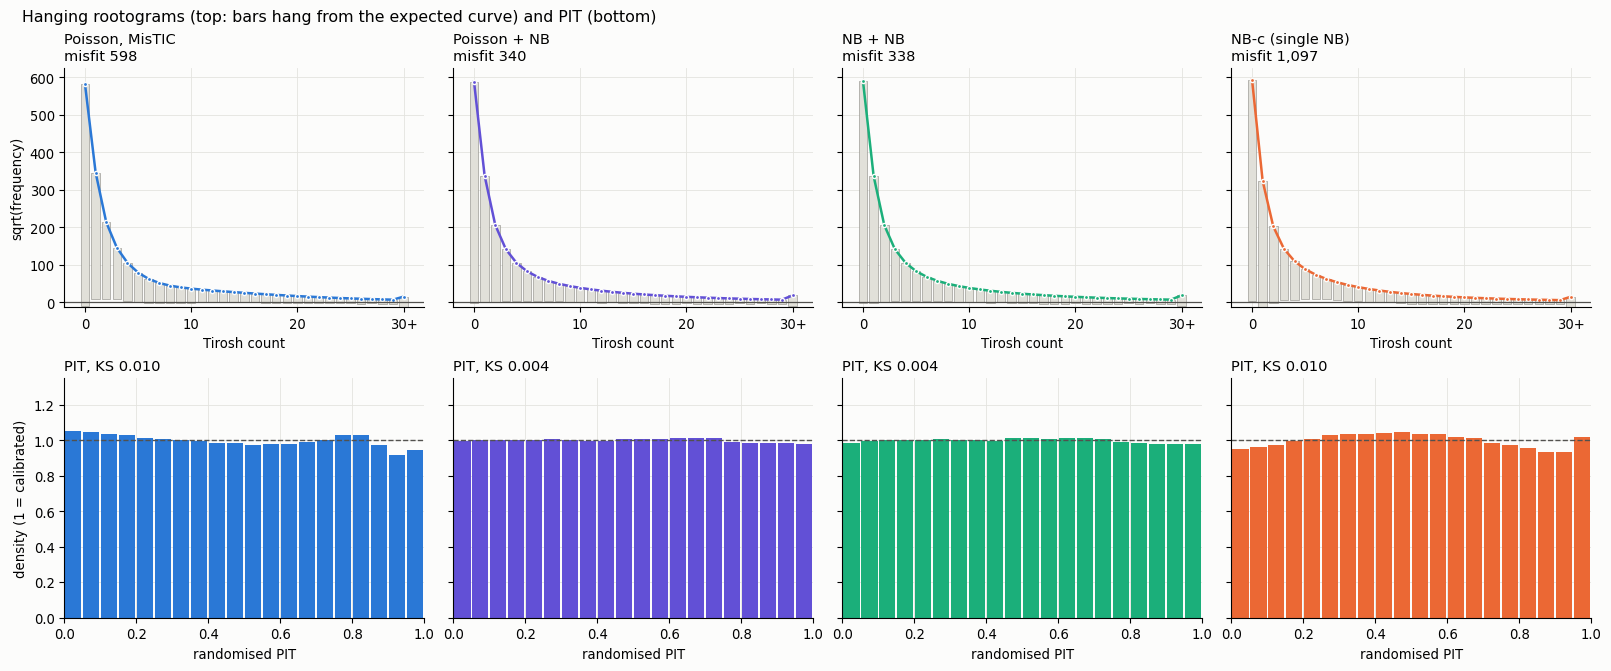

In [6]:
obs = np.array([np.sum(y == j) for j in range(KMAX)] + [np.sum(y >= KMAX)], float)
kk = np.arange(KMAX + 1)
SHOW = [m for m in ORDER if m != "Poisson, plain"]   # §2 compares plain with MisTIC
fig, axes = plt.subplots(2, len(SHOW), figsize=(4.0 * len(SHOW), 6.6), sharey="row", constrained_layout=True)
for j, m in enumerate(SHOW):
    e, o = np.sqrt(FITS[m]["expected"]), np.sqrt(obs)
    ax = axes[0, j]
    ax.bar(kk, o, bottom=e - o, width=0.8, color="#e1e0d9", edgecolor=MUTED, lw=0.4)
    ax.plot(kk, e, "-o", color=COL[m], lw=1.8, ms=3, mec="#fcfcfb")
    ax.axhline(0, color=INK2, lw=0.9)
    ax.set_xticks([0, 10, 20, 30]); ax.set_xticklabels(["0", "10", "20", "30+"])
    ax.set_title(f"{m}\nmisfit {ROWS[m]['rootogram misfit']:,.0f}", loc="left")
    ax.set_xlabel("Tirosh count")
    ax = axes[1, j]
    ax.bar(np.arange(20) / 20 + 0.025, np.histogram(FITS[m]["u"], 20, (0, 1))[0] / (n / 20),
           width=0.045, color=COL[m])
    ax.axhline(1, color=INK2, lw=1, ls="--"); ax.set_ylim(0, 1.35); ax.set_xlim(0, 1)
    ax.set_title(f"PIT, KS {ROWS[m]['PIT KS']:.3f}", loc="left"); ax.set_xlabel("randomised PIT")
axes[0, 0].set_ylabel("sqrt(frequency)"); axes[1, 0].set_ylabel("density (1 = calibrated)")
fig.suptitle("Hanging rootograms (top: bars hang from the expected curve) and PIT (bottom)", x=0.01, ha="left")
plt.show()

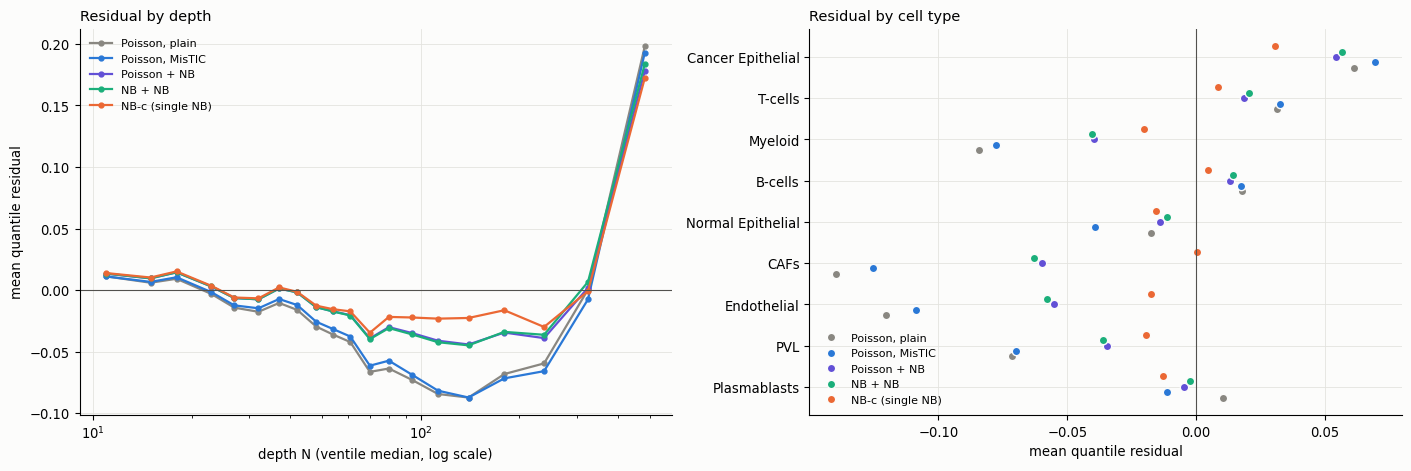

In [7]:
dec = pd.qcut(np.log(N), 20, labels=False, duplicates="drop")
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), constrained_layout=True)
for m in ORDER:
    r = stats.norm.ppf(FITS[m]["u"])
    g = pd.DataFrame({"d": dec, "r": r, "N": N}).groupby("d").agg(r=("r", "mean"), N=("N", "median"))
    axes[0].plot(g["N"], g["r"], "-o", color=COL[m], ms=3.5, lw=1.6, label=m)
    t = pd.DataFrame({"t": ctype, "r": r}).groupby("t")["r"].mean().reindex(TYPES)
    off = (ORDER.index(m) - 2) * 0.13
    axes[1].plot(t.to_numpy(), np.arange(len(TYPES))[::-1] + off, "o", color=COL[m], ms=6, mec="#fcfcfb", label=m)
for ax in axes: ax.axhline(0, color=INK2, lw=0.8) if ax is axes[0] else ax.axvline(0, color=INK2, lw=0.8)
axes[0].set_xscale("log"); axes[0].set_xlabel("depth N (ventile median, log scale)")
axes[0].set_ylabel("mean quantile residual"); axes[0].set_title("Residual by depth", loc="left")
axes[0].legend(fontsize=8, frameon=False)
axes[1].set_yticks(np.arange(len(TYPES))[::-1]); axes[1].set_yticklabels(TYPES)
axes[1].set_xlabel("mean quantile residual"); axes[1].set_title("Residual by cell type", loc="left")
axes[1].legend(fontsize=8, frameon=False, loc="lower left")
plt.show()

### Reading §5

**For the counts themselves, the NB mixtures are the best models here by a wide
margin.**
- AIC is 17,871 (Poisson + NB) and 18,034 (NB + NB) below the production mixture.
- They are 5,000-5,200 below the covariate-matched single NB (NB-c), which is itself
  12,849 below production, with one parameter fewer. On likelihood, one constant
  dispersion without a latent class beats the Poisson mixture's latent class; the NB
  mixtures, which have both, beat each.
- The plain Poisson mixture is 7,812 above production.

**Calibration ranks the models the same way.**
- Rootogram misfit is 338–340 for the NB mixtures, 598–600 for the Poisson
  mixtures, and 1,097 for NB-c.
- NB-c's likelihood beats the Poisson mixtures, but its count distribution is the
  worst. It over-predicts zeros (62.8% against 62.2%), and its PIT is hump-shaped:
  its predictive spread is too wide for typical cells (KS 0.010, the same distance
  from uniform as the Poisson mixtures', in the opposite shape).
- The Poisson mixtures' PIT is short in the top bins. Only the NB mixtures are flat
  (KS 0.004).

**What none of them fixes.**
- Every model under-predicts the deepest cells: the mean residual in the top depth
  ventile is +0.17 to +0.20 for all five.
- Between depths of about 70 and 300, the Poisson mixtures over-predict (down to
  −0.087). The NB mixtures halve that, and NB-c is flattest (−0.02 to −0.035).
- By type, the Poisson mixtures over-predict stroma (CAFs −0.12, Endothelial −0.11).
  The NB mixtures halve this, and NB-c nearly removes it (CAFs 0.00, Endothelial
  −0.02); it also halves the tumour's under-prediction.
- Residual Moran's I is 0.038–0.054 in every MisTIC model (NB-c lowest). Space is
  largely accounted for in all of them.

The rootogram and PIT figure leaves out the plain Poisson mixture, which §2 compares
with MisTIC; it is in the table above and the residual plots.

## 6. What $\pi$ becomes

The same weight block, refitted under each component family. Under Poisson
components $\pi$ is read as the probability of cycling. Once a component is NB, it
can absorb variation that the Poisson model had to explain by moving cells between
classes, so the split is no longer only about cycling. The table gives each
model's mean $\pi$ by cell type, its rate ratio, and how closely its $\pi$ ranks
cells like the production fit's.

,"Poisson, plain","Poisson, MisTIC",Poisson + NB,NB + NB
Cancer Epithelial,0.205,0.197,0.545,0.507
T-cells,0.108,0.109,0.377,0.344
Myeloid,0.049,0.048,0.165,0.146
B-cells,0.090,0.090,0.319,0.290
Normal Epithelial,0.107,0.100,0.306,0.275
CAFs,0.024,0.024,0.088,0.076
Endothelial,0.041,0.041,0.136,0.121
PVL,0.064,0.062,0.201,0.180
Plasmablasts,0.125,0.117,0.364,0.329
all cells,0.101,0.098,0.307,0.280


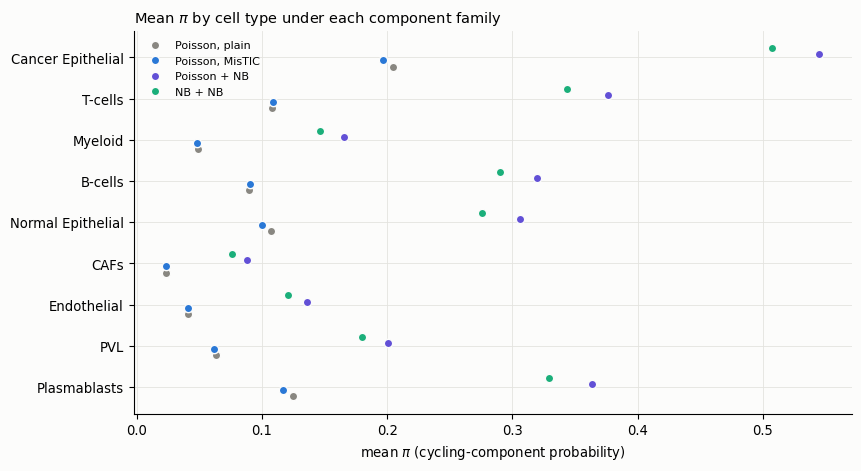

In [8]:
MIX = ["Poisson, plain", "Poisson, MisTIC", "Poisson + NB", "NB + NB"]
frac = pd.DataFrame({m: pd.Series(FITS[m]["pi"]).groupby(ctype).mean().reindex(TYPES) for m in MIX})
frac.loc["all cells"] = [FITS[m]["pi"].mean() for m in MIX]
rr = {"Poisson, plain": np.exp(pe["plain"]["e_delta"]), "Poisson, MisTIC": np.exp(pe["MisTIC"]["e_delta"]),
      "Poisson + NB": np.exp(np.exp(PNB["delta"])), "NB + NB": np.exp(np.exp(NBNB["delta"]))}
frac.loc["rate ratio"] = [rr[m] for m in MIX]
frac.loc["Spearman with production pi"] = [stats.spearmanr(FITS[m]["pi"], FITS["Poisson, MisTIC"]["pi"]).statistic
                                           for m in MIX]
display(frac.round(3))

fig, ax = plt.subplots(figsize=(8.5, 4.6), constrained_layout=True)
for j, m in enumerate(MIX):
    v = frac.loc[TYPES, m].to_numpy()
    ax.plot(v, np.arange(len(TYPES))[::-1] + (j - 1.5) * 0.15, "o", color=COL[m], ms=6, mec="#fcfcfb", label=m)
ax.set_yticks(np.arange(len(TYPES))[::-1]); ax.set_yticklabels(TYPES)
ax.set_xlabel(r"mean $\pi$ (cycling-component probability)"); ax.legend(fontsize=8, frameon=False)
ax.set_title(r"Mean $\pi$ by cell type under each component family", loc="left")
plt.show()

### Reading §6

**The NB families rescale $\pi$ but barely re-rank cells.**
- Spearman with production $\pi$ is 0.988 (Poisson + NB) and 0.989 (NB + NB).
- Mean $\pi$ rises about threefold in every type. Cancer Epithelial goes from 0.197
  to 0.545 and 0.507; CAFs from 0.024 to 0.088 and 0.076; T-cells from 0.109 to
  0.377 and 0.344.
- The rate ratio falls from 6.7 to 4.2.

**The neighbourhood contrasts mostly survive.** On the logit scale (top against
bottom decile of neighbourhood Cancer Epithelial score; `outputs/poisson_nb`,
`outputs/nb_nb`), most types move by 0.2 or less. Cancer Epithelial stays at 0.12
and PVL at 3.2–3.3. T-cells rise from 0.93 to 1.49.

**The reading.** Under NB components, $\pi$ is the probability of belonging to the
raised-expression class. That class holds about 30% of cells, so $\pi$ is not a
cycling fraction. Which cells and neighbourhoods are more likely to be cycling is
much the same under every family; how many are cycling depends on the family. The
production model keeps Poisson components so that $\pi$ stays interpretable as a
cycling probability. The NB mixtures are the better models of the counts.

## 7. The production fit: restarts, intervals and the interaction $B$

The production model is §2's MisTIC Poisson mixture. Its restarts are the 20-task
Spartan `multistart` job; its intervals come from 300 spatial-block bootstrap
replicates (about 250 contiguous tiles, drawn with replacement, each replicate
warm-started from the point estimate). Restart 0 starts with $U = V = 0$, a saddle
of the bilinear term, so it cannot fit the interaction and always sits apart.

In [9]:
ms = load_job("outputs/hpc", "multistart")
ll = ms["loglik"].to_numpy()
print(f"multistart: {ms['converged'].sum()}/{len(ms)} converged; {np.mean(ll > ll.max() - 1e-6):.0%} within 1e-6 "
      f"of the best; restart 0 is {ll.max() - ll[ms['restart'].to_numpy() == 0][0]:,.0f} below it")
b = boot["MisTIC"]
sig1 = np.array([s[0] for s in b["sigma"]])
pd.DataFrame({"estimate": [pe["MisTIC"]["mean_w"], np.exp(pe["MisTIC"]["e_delta"]), pe["MisTIC"]["theta_m"],
                           pe["MisTIC"]["entropy"],
                           np.linalg.svd(np.asarray(P0["U"]) @ np.asarray(P0["V"]).T, compute_uv=False)[0]],
              "2.5%": [np.percentile(b["mean_w"], 2.5), np.percentile(np.exp(b["e_delta"]), 2.5),
                       np.percentile(b["theta_m"], 2.5), np.percentile(b["entropy"], 2.5), np.percentile(sig1, 2.5)],
              "97.5%": [np.percentile(b["mean_w"], 97.5), np.percentile(np.exp(b["e_delta"]), 97.5),
                        np.percentile(b["theta_m"], 97.5), np.percentile(b["entropy"], 97.5), np.percentile(sig1, 97.5)]},
             index=["cycling fraction (mean w)", "rate ratio exp(e^delta)", "theta_m", "normalised entropy",
                    "sigma_1(B)"]).round(4)

multistart: 20/20 converged; 95% within 1e-6 of the best; restart 0 is 1,496 below it


,estimate,2.5%,97.5%
cycling fraction (mean w),0.0982,0.0934,0.1029
rate ratio exp(e^delta),6.6994,6.5740,6.8556
theta_m,1.5938,1.5329,1.6613
normalised entropy,0.7632,0.7538,0.7722
sigma_1(B),0.4119,0.3936,0.4447


The archetype-conditional neighbourhood effects (spec 8.2) — for a cell whose
own state sits at an archetype centroid, the odds ratio of cycling per IQR of each
neighbourhood component, with bootstrap intervals — are computed by
`run/estimands_report.py` and shown here from `outputs/estimands_8_2.md`.

In [10]:
Markdown(open("outputs/estimands_8_2.md").read())

# Spec 8.2 — archetype-conditional neighbourhood effects

Odds ratio of cycling per IQR of each neighbourhood component, for a cell whose own state sits at the given archetype centroid. `c + B^T phi_a`, mapped back to cell types. 95% CIs from the spatial block bootstrap; **bold** where the CI excludes 1.

| own archetype | c: Endothelial | c: CAFs | c: PVL | c: B-cells | c: T-cells | c: Myeloid | c: Normal Epithelial | c: Plasmablasts | c: Cancer Epithelial | r: Endothelial | r: CAFs | r: PVL | r: B-cells | r: T-cells | r: Myeloid | r: Normal Epithelial | r: Plasmablasts | r: Cancer Epithelial |
|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|---|
| Endothelial | **0.87** | **0.95** | **0.86** | **1.05** | **1.19** | **0.91** | **1.09** | 1.04 | **2.01** | **0.82** | 0.99 | 0.98 | 1.05 | **1.14** | 1.09 | 0.92 | 1.04 | **1.54** |
| CAFs | **0.93** | **0.96** | **0.95** | 1.01 | 1.05 | 0.95 | 1.05 | 0.96 | **1.84** | **0.91** | **0.94** | 1.02 | 0.98 | **1.17** | **1.15** | 1.07 | **0.87** | **1.44** |
| PVL | **0.87** | 0.95 | **0.85** | **1.06** | **1.20** | 0.98 | 1.10 | 1.00 | **1.98** | **0.86** | 0.97 | **0.93** | **1.08** | **1.20** | **1.22** | 0.98 | 0.91 | **1.80** |
| B-cells | **0.94** | **0.96** | 0.99 | **0.97** | **0.93** | **0.86** | **1.11** | 0.97 | **2.08** | **0.88** | 0.96 | **1.11** | **0.92** | **1.09** | 0.96 | 1.13 | 0.97 | 1.17 |
| T-cells | **0.92** | **0.96** | 0.97 | **0.97** | **0.93** | **0.86** | **1.14** | **0.97** | **2.21** | **0.87** | 0.96 | **1.10** | **0.93** | **1.11** | 0.98 | 1.17 | 0.94 | **1.26** |
| Myeloid | **0.92** | **0.95** | 0.97 | 0.98 | 0.99 | **0.80** | **1.09** | 1.04 | **2.05** | **0.81** | 1.00 | **1.14** | **0.91** | 1.03 | **0.86** | 0.98 | **1.19** | 1.02 |
| Normal Epithelial | **0.95** | **0.95** | **0.97** | **1.04** | **1.29** | **0.93** | **0.85** | **1.05** | **1.22** | **0.86** | 0.99 | **1.06** | **0.94** | 1.08 | 1.07 | **0.73** | **1.24** | 1.02 |
| Plasmablasts | **0.96** | 0.96 | 0.98 | 1.03 | **1.14** | 1.00 | 0.94 | **0.96** | **1.46** | 0.95 | **0.94** | 1.01 | 0.98 | **1.19** | **1.24** | 0.96 | **0.89** | **1.36** |
| Cancer Epithelial | **0.96** | **0.95** | 0.98 | **1.05** | **1.32** | **0.93** | **0.83** | **1.06** | **1.16** | **0.86** | 0.99 | **1.06** | **0.94** | 1.08 | 1.08 | **0.70** | **1.26** | 1.00 |

102 of 162 entries have a CI excluding 1.


## 8. Where the rest lives

- **Penalty and rank** (λ = 300, rank 3, re-checked under MisTIC): `outputs/penalty/report.md`.
- **Depth exponent pinned against free:** `outputs/theta_bracket/report.md`.
- **MisTIC against plain, the full report** (held out, estimands, label rates): `outputs/baseline/report.md`.
- **Simulation tests 01–08:** `outputs/validation_report.md`.
- **NB regressions** (technical terms, depth, NB-c against NB-d, oxygen, neighbourhood): `notebooks/nb_baseline.ipynb`.
- **The division classifier comparison:** `outputs/division_classifier/report.md`.
- **The phase portrait:** `outputs/portrait/FINDINGS.md`.
- **The ovarian section:** the same models, `outputs/hpc_ovarian`, `outputs/poisson_nb_ovarian`, `outputs/nb_nb_ovarian`.
- **Which model produced each output folder:** `outputs/README.md`.